# Razão e limites cruzados

**Uma vazão precisa acompanhar a outra. Nos transitórios, a ordem importa.**

Comparar dois comandos: pedir ar e combustível juntos, ou permitir mais
combustível só depois de o ar chegar. Execute de cima para baixo; o painel está no fim.

In [1]:
%pip -q install control==0.10.2 scipy matplotlib ipywidgets

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as controles
import control as sistema
from scipy import signal
from scipy.optimize import least_squares
from IPython.display import display

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

plt.rcParams.update({"figure.figsize": (9, 3), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})

## O processo

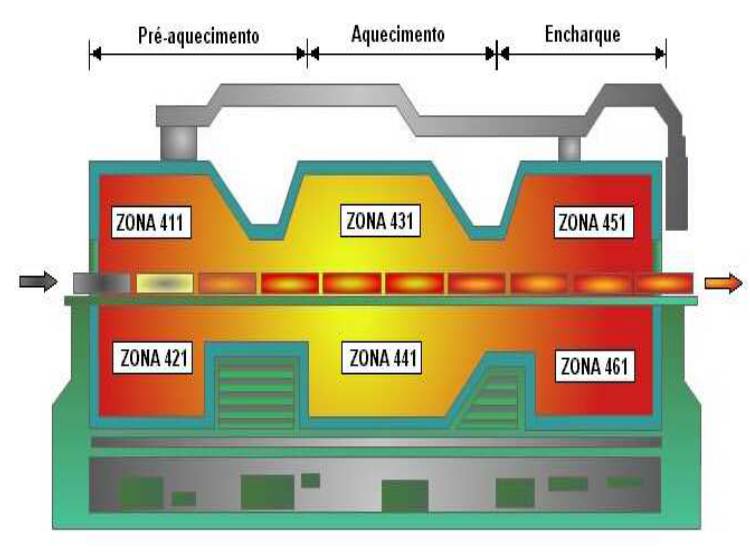

Duas válvulas alimentam uma zona de um forno. Usar modelos publicados para
as malhas de gás e ar, em desvios em relação ao ponto de operação:

$$G_g(s)=\frac{0{,}25e^{-s}}{4{,}78s+1},\qquad
G_a(s)=\frac{0{,}51e^{-2s}}{7{,}16s+1}.$$

Entrada: abertura em pontos percentuais. Saída: desvio de vazão em mil Nm³/h.
O tempo está em segundos. No painel, normalizar os fluxos para enxergar a sequência;
a razão escolhida ali **não é uma razão estequiométrica do forno**.

In [3]:
nomes = ['Gás', 'Ar']
modelos = np.array([[0.25, 4.78, 1.0], [0.51, 7.16, 2.0]])  # K, τ, θ
unidade_tempo = 'Tempo (s)'
unidade_saida = 'Desvio de vazão (mil Nm³/h)'

## Primeiro, só a regra

Ao pedir 0,60 de combustível, se o ar disponível só permitir 0,40, o seletor
limita o pedido. O `min` segura o combustível; o `max` mantém o pedido de ar.

In [4]:
def referencias_cruzadas(demanda, combustivel, ar, razao):
    referencia_ar = max(razao * demanda, razao * combustivel)
    referencia_combustivel = min(demanda, ar / razao)
    return np.array([referencia_combustivel, referencia_ar])

pedido = referencias_cruzadas(demanda=0.60, combustivel=0.30, ar=0.44, razao=1.10)
print(f'Combustível permitido: {pedido[0]:.2f}; pedido de ar: {pedido[1]:.2f}')

Combustível permitido: 0.40; pedido de ar: 0.66


## Os ensaios

Separar **ensaio → dados → identificação → escolha → validação → IMC**.
Gerar três ensaios diferentes por canal, com ruído, e salvar os arquivos CSV.
Estes dados são simulados; a identificação terá acesso apenas aos arquivos.

Para usar dados próprios, enviar os seis CSV para `dados_ensaio/` e mudar
`usar_ensaio_externo` para `True`. Usar `tempo,entrada,saida`, amostragem uniforme
e variáveis em desvio do ponto de operação; iniciar em equilíbrio com entrada zero.

In [5]:
def guardar_ensaio(nome, tempo, entrada, saida):
    pasta = Path('dados_ensaio')
    pasta.mkdir(exist_ok=True)
    np.savetxt(pasta / f'{nome}.csv', np.column_stack([tempo, entrada, saida]),
               delimiter=',', header='tempo,entrada,saida', comments='')

In [6]:
def resposta_modelo(tempo, entrada, parametros):
    ganho, constante, atraso = parametros
    variacoes = np.diff(entrada, prepend=0)
    saida = np.zeros_like(tempo)
    for indice in np.flatnonzero(variacoes):
        decorrido = np.maximum(tempo - tempo[indice] - atraso, 0)
        saida += ganho * variacoes[indice] * (1 - np.exp(-decorrido / constante))
    return saida

In [7]:
usar_ensaio_externo = False
canais = ['gas', 'ar']

if not usar_ensaio_externo:
    tempo_ensaio = np.arange(0, 90 + 0.25 / 2, 0.25)
    entradas = {
        'ajuste': np.where(tempo_ensaio >= 5, 5.0, 0.0),
        'escolha': np.select([tempo_ensaio < 5, tempo_ensaio < 25,
                               tempo_ensaio < 50, tempo_ensaio < 70],
                              [0, 3, -2, 4], default=1).astype(float),
        'validacao': np.select([tempo_ensaio < 5, tempo_ensaio < 20,
                               tempo_ensaio < 40, tempo_ensaio < 60,
                               tempo_ensaio < 75],
                              [0, 2, 4, -1, 3], default=0).astype(float)}
    for numero, (etapa, entrada) in enumerate(entradas.items()):
        gerador = np.random.default_rng(8300 + numero)
        for canal, planta in zip(canais, modelos):
            medicao = resposta_modelo(tempo_ensaio, entrada, planta)
            medicao += gerador.normal(0, 0.025, len(tempo_ensaio))
            guardar_ensaio(f'{etapa}_{canal}', tempo_ensaio, entrada, medicao)
    print('Salvar três ensaios por canal em dados_ensaio/.')

Salvar três ensaios por canal em dados_ensaio/.


## Ler os dados

Ler os arquivos sem fornecer os parâmetros da planta ao identificador.
Reservar o último ensaio para conferir o modelo depois da escolha.

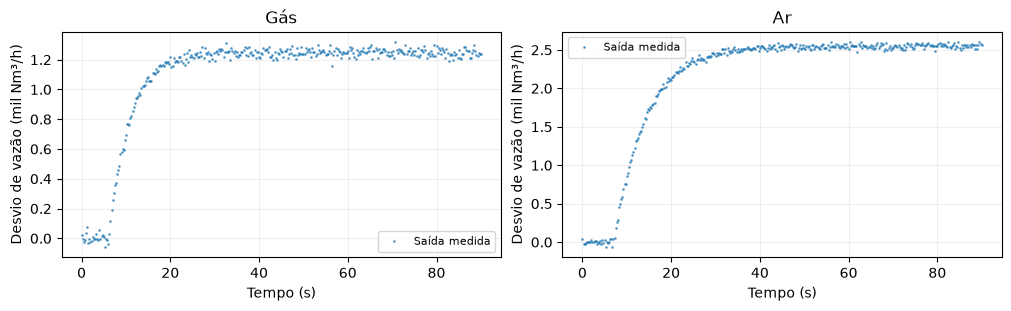

In [8]:
def ler_ensaio(nome):
    dados = np.genfromtxt(Path('dados_ensaio') / f'{nome}.csv', delimiter=',', names=True)
    tempo, entrada, saida = [np.asarray(dados[c], float) for c in ('tempo', 'entrada', 'saida')]
    if len(tempo) < 20 or not np.all(np.isfinite([tempo, entrada, saida])):
        raise ValueError('Fornecer pelo menos 20 amostras finitas de tempo, entrada e saída.')
    if not np.all(np.diff(tempo) > 0) or not np.allclose(np.diff(tempo), np.diff(tempo)[0]):
        raise ValueError('Usar amostragem uniforme, com tempo crescente.')
    if abs(entrada[0]) > 1e-10:
        raise ValueError('Remover o ponto de operação da entrada; iniciar em desvio zero.')
    return tempo - tempo[0], entrada, saida

ensaios = {canal: {etapa: ler_ensaio(f'{etapa}_{canal}')
                  for etapa in ('ajuste', 'escolha', 'validacao')}
           for canal in canais}
figura, eixos = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for canal, nome, eixo in zip(canais, nomes, eixos):
    tempo, entrada, saida = ensaios[canal]['ajuste']
    eixo.plot(tempo, saida, '.', ms=2, alpha=0.6, label='Saída medida')
    eixo.set(title=nome, xlabel=unidade_tempo, ylabel=unidade_saida)
    eixo.legend(fontsize=8)
plt.show()

## Identificar P1D, P2D ou P3D

Testar um, dois ou três polos reais estáveis, sempre com atraso identificado:
P1D: $G(s)=K e^{-\theta s}/(\tau_1 s+1)$. Para P2D e P3D, acrescentar um ou dois fatores $(\tau_i s+1)$ ao denominador.
P1D tem 3 parâmetros; P2D, 4; P3D, 5. Ajustar somente no ensaio de ajuste.

In [9]:
def prever_modelo(modelo, ensaio):
    tempo, entrada, _ = ensaio
    denominador = np.array([1.0])
    for constante in modelo['constantes']:
        denominador = np.convolve(denominador, [constante, 1.0])
    entrada_atrasada = np.interp(tempo - modelo['atraso'], tempo, entrada, left=0)
    numerador, denominador, _ = signal.cont2discrete(
        ([modelo['ganho']], denominador), tempo[1] - tempo[0], method='zoh')
    return signal.lfilter(numerador.ravel(), denominador, entrada_atrasada)

def avaliar_modelo(modelo, ensaio):
    previsao = prever_modelo(modelo, ensaio)
    erro = ensaio[2] - previsao
    escala = np.linalg.norm(ensaio[2] - np.mean(ensaio[2]))
    ajuste = 100 * (1 - np.linalg.norm(erro) / escala) if escala > 0 else np.nan
    return ajuste, np.sqrt(np.mean(erro ** 2))

In [10]:
def identificar_modelo(ensaio, ordem):
    tempo, entrada, saida = ensaio
    duracao, passo = tempo[-1], tempo[1] - tempo[0]
    cauda = slice(-max(10, len(tempo) // 10), None)
    ganho_inicial = abs(np.median(saida[cauda]) / np.median(entrada[cauda]))
    if not np.isfinite(ganho_inicial) or ganho_inicial <= 0:
        raise ValueError('Usar um ensaio de ajuste com patamar final diferente de zero.')
    def montar(parametros):
        return {'ganho': parametros[0], 'constantes': np.sort(parametros[1:-1]),
                'atraso': parametros[-1], 'parametros': ordem + 2}
    limites = ([ganho_inicial / 20] + [passo / 10] * ordem + [0],
               [ganho_inicial * 20] + [duracao * 2] * ordem + [duracao / 4])
    ajustes = []
    for fracao in (0.06, 0.18):
        constantes = (np.geomspace(max(passo / 5, duracao * 0.002), duracao * fracao, ordem)
                      if ordem > 1 else [duracao * fracao])
        inicio = [ganho_inicial, *constantes, passo]
        ajuste = least_squares(lambda p: prever_modelo(montar(p), ensaio) - saida,
                               inicio, bounds=limites, x_scale='jac', max_nfev=250)
        ajustes.append(ajuste)
    melhor = min(ajustes, key=lambda resultado: resultado.cost)
    if not melhor.success:
        raise RuntimeError('O ajuste não convergiu; revisar o ensaio antes da sintonia.')
    return montar(melhor.x)

In [11]:
candidatos = {canal: {f'P{ordem}D': identificar_modelo(ensaios[canal]['ajuste'], ordem)
                       for ordem in (1, 2, 3)} for canal in canais}
print('Ajustar somente os dados do primeiro ensaio.')

Ajustar somente os dados do primeiro ensaio.


## Escolher com parcimônia

Comparar o **FIT em outro ensaio**. Aceitar até 1 ponto percentual abaixo do melhor
FIT e preferir menos parâmetros. Um modelo maior só compensa se melhorar o resultado.

In [12]:
def escolher_modelo(candidatos, ensaio_escolha, tolerancia=1.0):
    ajustes = {nome: avaliar_modelo(modelo, ensaio_escolha)[0]
               for nome, modelo in candidatos.items()}
    melhor = max(ajustes.values())
    elegiveis = [nome for nome in candidatos if ajustes[nome] >= melhor - tolerancia]
    return min(elegiveis, key=lambda nome: (candidatos[nome]['parametros'], -ajustes[nome]))

def reduzir_modelo(modelo):
    return np.array([modelo['ganho'], np.sum(modelo['constantes']), modelo['atraso']])

selecionados = {canal: escolher_modelo(candidatos[canal], ensaios[canal]['escolha'])
                for canal in canais}
print(f'{"Canal":<20} {"Modelo":<8} {"Parâmetros":>10} {"FIT escolha":>12}  Seleção')
for canal, nome in zip(canais, nomes):
    for estrutura, modelo in candidatos[canal].items():
        ajuste, _ = avaliar_modelo(modelo, ensaios[canal]['escolha'])
        marca = '← parcimonioso' if estrutura == selecionados[canal] else ''
        print(f'{nome:<20} {estrutura:<8} {modelo["parametros"]:>10} {ajuste:>11.2f}%  {marca}')
estimativas = np.array([reduzir_modelo(candidatos[canal][selecionados[canal]])
                        for canal in canais])

Canal                Modelo   Parâmetros  FIT escolha  Seleção
Gás                  P1D               3       94.69%  ← parcimonioso
Gás                  P2D               4       94.69%  
Gás                  P3D               5       94.69%  
Ar                   P1D               3       96.84%  ← parcimonioso
Ar                   P2D               4       96.82%  
Ar                   P3D               5       96.82%  


## Validar sem reajustar

Usar o terceiro ensaio com os modelos já escolhidos. Comparar as curvas e o RMSE;
um FIT alto no ensaio de escolha não substitui esta conferência.

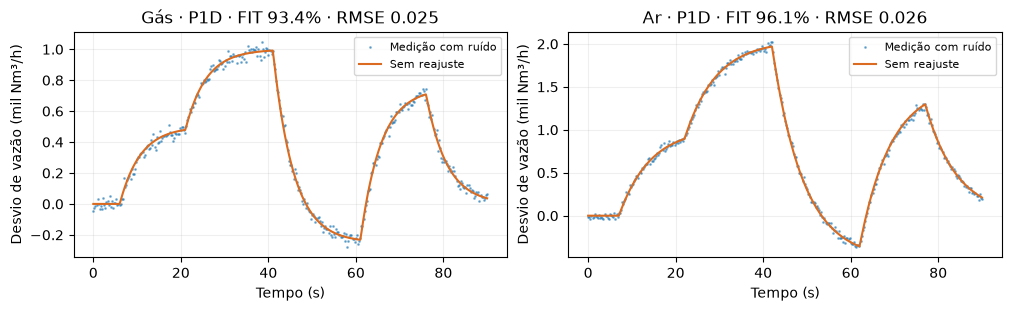

In [13]:
figura, eixos = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for canal, nome, eixo in zip(canais, nomes, eixos):
    ensaio = ensaios[canal]['validacao']
    modelo = candidatos[canal][selecionados[canal]]
    ajuste, rmse = avaliar_modelo(modelo, ensaio)
    eixo.plot(ensaio[0], ensaio[2], '.', ms=2, alpha=0.5, label='Medição com ruído')
    eixo.plot(ensaio[0], prever_modelo(modelo, ensaio), color='#db6b20', label='Sem reajuste')
    eixo.set(title=f'{nome} · {selecionados[canal]} · FIT {ajuste:.1f}% · RMSE {rmse:.3f}',
             xlabel=unidade_tempo, ylabel=unidade_saida)
    eixo.legend(fontsize=8)
plt.show()

## Sintonia IMC

Usar as estimativas: $K_c=\tau/[K(\lambda+\theta)]$ e $T_i=\tau$.
Aqui, $\lambda=8$ s para as duas malhas. Assim, a comparação destaca a lógica de razão.
Normalizar os ganhos antes de usar o PI no painel.

Para P2D/P3D, reduzir para primeira ordem usando $\tau=\sum_i\tau_i$, mantendo
ganho e atraso. Essa aproximação preserva o primeiro momento; o PI-IMC usa
o modelo reduzido. A simulação final usa a seleção parcimoniosa.

In [14]:
def sintonia_imc(parametros, tempo_resposta):
    ganho, constante, atraso = parametros
    ganho_controlador = constante / (ganho * (tempo_resposta + atraso))
    tempo_integral = constante
    return ganho_controlador, tempo_integral

def comando_pi(erro, integral, ganho, tempo_integral, passo):
    tentativa = ganho * erro + integral
    comando = np.clip(tentativa, 0, 1)
    # Evitar acumular integral quando a ação empurra além do limite.
    if 0 < tentativa < 1 or (tentativa >= 1 and erro < 0) or (tentativa <= 0 and erro > 0):
        integral += ganho * erro * passo / tempo_integral
    return comando, integral

parametros_normalizados = estimativas.copy()
parametros_normalizados[:, 0] /= modelos[:, 0]
sintonias = np.array([sintonia_imc(parametros, 8) for parametros in parametros_normalizados])
print('Kc e Ti das malhas normalizadas:', np.round(sintonias, 3))

Kc e Ti das malhas normalizadas: [[0.521 4.702]
 [0.713 7.152]]


## Comparar as sintonias

Selecionar um ou mais modelos. Cada curva usa o PI-IMC obtido daquele modelo,
mas todos controlam **o mesmo canal da planta**. Alterar λ para observar a resposta.
Este painel serve para comparar; a experiência final mantém os modelos parcimoniosos.

In [15]:
def comparar_sintonias(canal=canais[0], estruturas=('P1D', 'P2D', 'P3D'), tempo_resposta=8):
    indice = canais.index(canal)
    ganho, constante, atraso = modelos[indice]
    numerador_atraso, denominador_atraso = sistema.pade(atraso, 3)
    planta = sistema.tf([ganho], [constante, 1]) * sistema.tf(numerador_atraso, denominador_atraso)
    tempo = np.linspace(0, 90, 500)
    figura, eixo = plt.subplots(figsize=(9, 3))
    for estrutura in estruturas:
        parametros = reduzir_modelo(candidatos[canal][estrutura])
        ganho_pi, tempo_integral = sintonia_imc(parametros, tempo_resposta)
        controlador = sistema.tf([ganho_pi * tempo_integral, ganho_pi], [tempo_integral, 0])
        malha = sistema.feedback(controlador * planta)
        if np.any(sistema.poles(malha).real >= 0):
            print(f'{estrutura}: sintonia instável; aumentar λ.')
            continue
        _, resposta = sistema.step_response(malha, tempo)
        eixo.plot(tempo, resposta, label=f'{estrutura} · Kc={ganho_pi:.2f}, Ti={tempo_integral:.2f}')
    eixo.axhline(1, color='#666666', ls='--', label='Referência')
    eixo.set(title=f'{nomes[indice]} · comparar na mesma planta',
             xlabel=unidade_tempo, ylabel=unidade_saida)
    eixo.legend(fontsize=8)
    plt.show()

painel_sintonia = controles.interactive(
    comparar_sintonias,
    canal=controles.Dropdown(options=list(zip(nomes, canais)), description='Canal'),
    estruturas=controles.SelectMultiple(options=['P1D', 'P2D', 'P3D'],
                                        value=('P1D', 'P2D', 'P3D'), description='Modelos'),
    tempo_resposta=controles.IntSlider(value=8, min=8, max=24, step=2,
                                       description='IMC λ', continuous_update=False))
display(painel_sintonia)

interactive(children=(Dropdown(description='Canal', options=(('Gás', 'gas'), ('Ar', 'ar')), value='gas'), Sele…

## A simulação

A demanda sobe em 40 s e volta em 140 s. As duas estratégias usam os mesmos modelos,
PIs e ruído. Na curva superior, valores abaixo da razão-alvo mostram falta relativa
de ar. A curva inferior mostra quem avança primeiro com os limites cruzados.

In [16]:
def simular_razao(demanda_final=0.65, razao=1.10, ruido=0.003, cruzado=True, passo=0.05):
    tempo = np.arange(0, 240 + passo / 2, passo)
    demanda = np.where((tempo >= 40) & (tempo < 140), demanda_final, 0.30)
    vazoes = np.zeros((len(tempo), 2))
    comandos = np.zeros_like(vazoes)
    vazoes[0] = [0.30, razao * 0.30]
    comandos[0] = vazoes[0]
    integrais = vazoes[0].copy()
    gerador = np.random.default_rng(42)
    atenuacoes = np.exp(-passo / modelos[:, 1])
    atrasos = np.rint(modelos[:, 2] / passo).astype(int)
    for indice in range(len(tempo) - 1):
        medidas = np.maximum(vazoes[indice] + gerador.normal(0, ruido, 2), 0)
        referencias = (referencias_cruzadas(demanda[indice], *medidas, razao)
                       if cruzado else np.array([demanda[indice], razao * demanda[indice]]))
        for canal in range(2):
            comandos[indice, canal], integrais[canal] = comando_pi(
                referencias[canal] - medidas[canal], integrais[canal],
                *sintonias[canal], passo)
            anterior = indice - atrasos[canal]
            atrasado = comandos[anterior, canal] if anterior >= 0 else vazoes[0, canal]
            vazoes[indice + 1, canal] = (atenuacoes[canal] * vazoes[indice, canal]
                                        + (1 - atenuacoes[canal]) * atrasado)
    comandos[-1] = comandos[-2]
    return tempo, vazoes, comandos

In [17]:
def explorar_razao(demanda_final=0.65, razao=1.10, ruido=0.003):
    tempo, vazoes_cruzadas, _ = simular_razao(demanda_final, razao, ruido, True)
    _, vazoes_paralelas, _ = simular_razao(demanda_final, razao, ruido, False)
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True, constrained_layout=True)
    for vazoes, nome, cor in [(vazoes_paralelas, 'Pedidos juntos', '#df752c'),
                              (vazoes_cruzadas, 'Limites cruzados', '#2374ab')]:
        proporcao = vazoes[:, 1] / vazoes[:, 0]
        eixos[0].plot(tempo, proporcao, label=nome, color=cor)
    eixos[0].axhline(razao, ls='--', color='#555555', label='Razão-alvo')
    eixos[0].set(ylabel='Ar / combustível', title='A proporção durante a mudança')
    eixos[0].legend(fontsize=8)
    eixos[1].plot(tempo, vazoes_cruzadas[:, 0], label='Combustível')
    eixos[1].plot(tempo, vazoes_cruzadas[:, 1] / razao, label='Ar equivalente')
    eixos[1].set(xlabel='Tempo (s)', ylabel='Fluxo normalizado', title='Com limites cruzados')
    eixos[1].legend(fontsize=8)
    plt.show()

painel_razao = controles.interactive(
    explorar_razao,
    demanda_final=controles.FloatSlider(value=0.65, min=0.40, max=0.75, step=0.05,
                                        description='Demanda', continuous_update=False),
    razao=controles.FloatSlider(value=1.10, min=1.00, max=1.30, step=0.05,
                                description='Razão-alvo', continuous_update=False),
    ruido=controles.FloatSlider(value=0.003, min=0, max=0.015, step=0.003,
                                description='Ruído (σ)', readout_format='.3f', continuous_update=False))
display(painel_razao)

interactive(children=(FloatSlider(value=0.65, continuous_update=False, description='Demanda', max=0.75, min=0.…

## O que observar

- **Demanda:** amplia a mudança; os seletores coordenam a subida e a descida.
- **Razão-alvo:** pede mais ar para a mesma demanda de combustível.
- **Ruído:** a lógica age sobre medições imperfeitas. Pode haver pequenas violações da razão.

Limites cruzados coordenam pedidos; não substituem proteção de uma combustão real.
A explicação completa e as referências estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/03_razao_limites_cruzados/README.md).

## Referências

1. Teixeira, B. O. S.; Jota, F. G.; Teixeira, M. H. (2007). *Modelagem, controle e otimização
do processo dos fornos de reaquecimento de placas*. SBA: Controle & Automação, 18(1), 67–93.
[Artigo](https://doi.org/10.1590/S0103-17592007000100006), Tabela 2 e seção 2. Imagem: Figura 2, p. 71.
2. Rivera, D. E.; Morari, M.; Skogestad, S. (1986). *Internal model control. 4. PID controller design*.
[DOI](https://doi.org/10.1021/i200032a041).